<a href="https://colab.research.google.com/github/vanitripathi24/UCS420/blob/main/ucs420_assgn9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install -q easyocr opencv-python-headless matplotlib pandas pillow


In [2]:

import cv2
import easyocr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import re
from PIL import Image
from google.colab import files

print("Libraries imported successfully!")


Libraries imported successfully!


Saving Screenshot 2026-11-16 183658.png to Screenshot 2026-11-16 183658.png


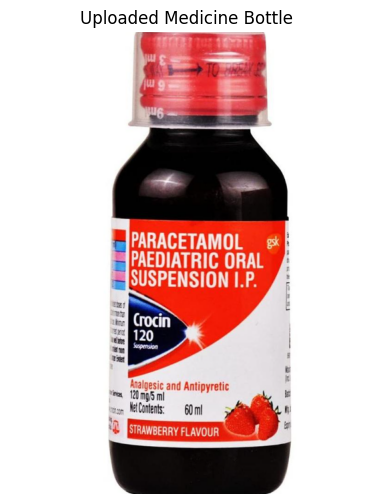

In [3]:

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(image_rgb)
plt.title("Uploaded Medicine Bottle")
plt.axis("off")
plt.show()


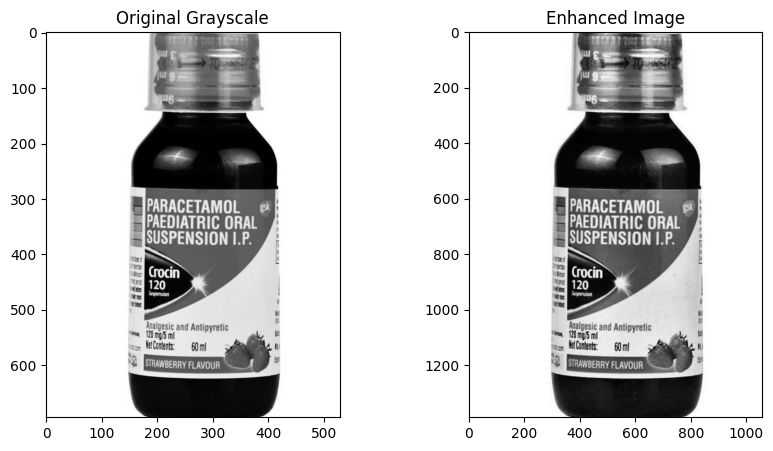

In [4]:

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Improve contrast
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

enhanced = clahe.apply(gray)

# Resize image
processed = cv2.resize(
    enhanced,
    None,
    fx=2,
    fy=2,
    interpolation=cv2.INTER_CUBIC
)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale")

plt.subplot(1, 2, 2)
plt.imshow(processed, cmap="gray")
plt.title("Enhanced Image")

plt.show()


In [5]:

reader = easyocr.Reader(['en'], gpu=False)

results = reader.readtext(processed)

extracted_text = []

print("EXTRACTED MEDICINE LABEL TEXT\n")

for result in results:
    text = result[1]
    confidence = result[2]

    extracted_text.append(text)

    print(f"{text}  | Confidence: {confidence:.2f}")

full_text = "\n".join(extracted_text)


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


EXTRACTED MEDICINE LABEL TEXT

JO  | Confidence: 0.05
0u6  | Confidence: 0.18
PARACETAMOL  | Confidence: 0.99
gk  | Confidence: 0.47
PAEDIATRIC ORAL  | Confidence: 1.00
SUSPENSION [.P  | Confidence: 0.58
(rocin  | Confidence: 0.67
120  | Confidence: 1.00
Sapauso  | Confidence: 0.01
Analgesic and Antipyretic  | Confidence: 0.43
I2Umg5 ml  | Confidence: 0.06
Helconents:  | Confidence: 0.13
6ml  | Confidence: 0.28
[STRAWBERRY FLAVOUR  | Confidence: 0.64
JW Ge  | Confidence: 0.06
w 9  | Confidence: 0.36


In [6]:

def extract_medicine_details(text):

    details = {}

    lines = [
        line.strip()
        for line in text.split("\n")
        if line.strip()
    ]

    details["Medicine Name"] = (
        lines[0] if lines else "Not detected"
    )

    dosage = re.findall(
        r'\b\d+(?:\.\d+)?\s*(?:mg|mcg|g|ml|IU|%)\b',
        text,
        re.IGNORECASE
    )

    details["Dosage"] = (
        ", ".join(dosage) if dosage else "Not detected"
    )

    expiry = re.findall(
        r'(?:EXP|Expiry|Expires)\s*[:\-]?\s*[\w/\-.]+',
        text,
        re.IGNORECASE
    )

    details["Expiry Date"] = (
        ", ".join(expiry) if expiry else "Not detected"
    )

    manufacturing = re.findall(
        r'(?:MFG|MFD|Manufactured)\s*[:\-]?\s*[\w/\-.]+',
        text,
        re.IGNORECASE
    )

    details["Manufacturing Date"] = (
        ", ".join(manufacturing)
        if manufacturing else "Not detected"
    )

    batch = re.findall(
        r'(?:Batch|B\.No|Lot)\s*[:\-]?\s*[\w-]+',
        text,
        re.IGNORECASE
    )

    details["Batch Number"] = (
        ", ".join(batch) if batch else "Not detected"
    )

    return details


medicine_details = extract_medicine_details(full_text)

print("\nMEDICINE INFORMATION\n")

for key, value in medicine_details.items():
    print(key, ":", value)




MEDICINE INFORMATION

Medicine Name : JO
Dosage : 6ml
Expiry Date : Not detected
Manufacturing Date : Not detected
Batch Number : Not detected


In [7]:

print("=" * 45)
print("       MEDICINE COGNITIVE ASSISTANT")
print("=" * 45)

for key, value in medicine_details.items():
    print(f"{key}: {value}")

print("\nAssistant: I have scanned your medicine label.")

print("Please verify the extracted details against "
      "the original packaging.")

print("=" * 45)


       MEDICINE COGNITIVE ASSISTANT
Medicine Name: JO
Dosage: 6ml
Expiry Date: Not detected
Manufacturing Date: Not detected
Batch Number: Not detected

Assistant: I have scanned your medicine label.
Please verify the extracted details against the original packaging.


In [8]:
##question 2


In [2]:

!pip install -q kaggle

from google.colab import files

uploaded = files.upload()  # Upload kaggle.json

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d msambare/fer2013

!unzip -q fer2013.zip -d /content/fer2013

print("FER2013 Dataset downloaded!")


Saving kaggle.json to kaggle (1).json
Dataset URL: https://www.kaggle.com/datasets/msambare/fer2013
License(s): DbCL-1.0
fer2013.zip: Skipping, found more recently modified local copy (use --force to force download)
replace /content/fer2013/test/angry/PrivateTest_10131363.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: FER2013 Dataset downloaded!


In [3]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from google.colab import files

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [4]:

DATASET_PATH = "/content/fer2013"

train_dir = os.path.join(DATASET_PATH, "train")
test_dir = os.path.join(DATASET_PATH, "test")

IMG_SIZE = 48
BATCH_SIZE = 64

train_data = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

test_data = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_data.class_names

print("Emotion classes:", class_names)


Found 28709 files belonging to 7 classes.
Found 7178 files belonging to 7 classes.
Emotion classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


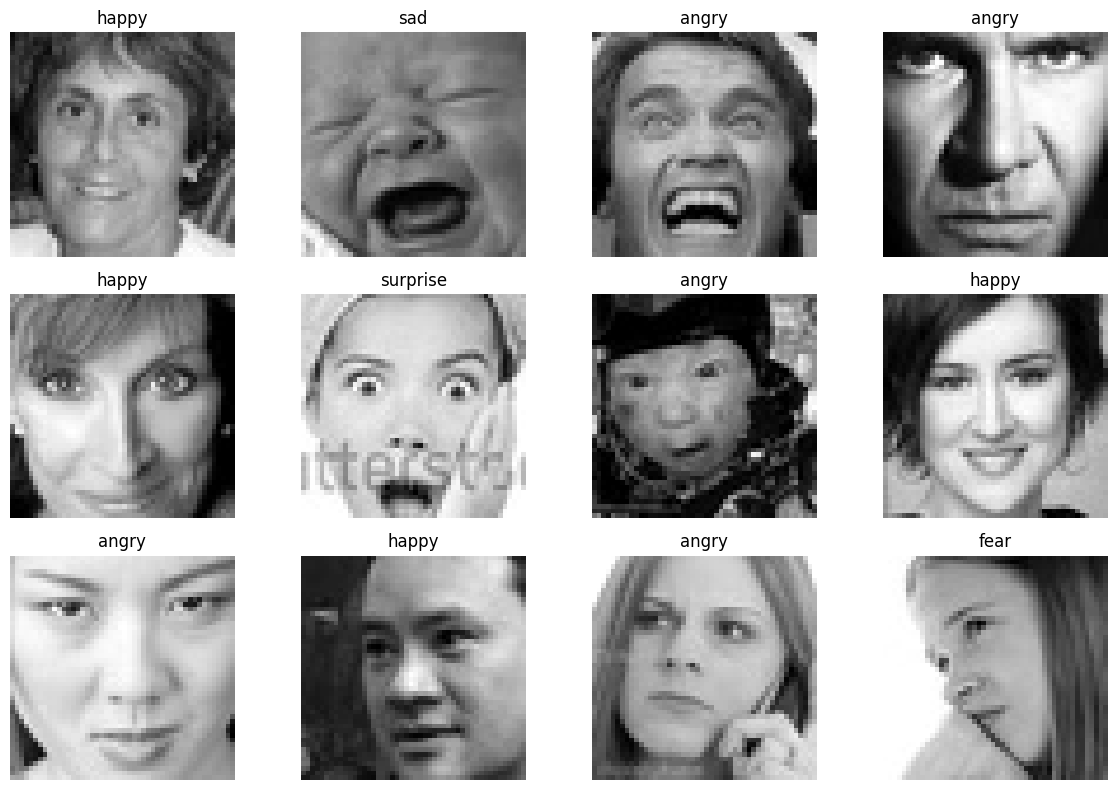

In [5]:

plt.figure(figsize=(12, 8))

for images, labels in train_data.take(1):

    for i in range(12):

        plt.subplot(3, 4, i + 1)

        plt.imshow(
            images[i].numpy().squeeze(),
            cmap="gray"
        )

        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()
plt.show()


In [6]:

model = models.Sequential([

    layers.Input(shape=(48, 48, 1)),

    layers.Rescaling(1./255),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(7, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,847 (1.36 MB)

 Trainable params: 355,847 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:

history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=10
)


Epoch 1/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 110s 240ms/step - accuracy: 0.3092 - loss: 1.7241 - val_accuracy: 0.4104 - val_loss: 1.5632
Epoch 2/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 103s 229ms/step - accuracy: 0.4187 - loss: 1.5069 - val_accuracy: 0.4730 - val_loss: 1.3912
Epoch 3/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 142s 229ms/step - accuracy: 0.4659 - loss: 1.3956 - val_accuracy: 0.4975 - val_loss: 1.3152
Epoch 4/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 145s 237ms/step - accuracy: 0.5018 - loss: 1.3121 - val_accuracy: 0.5194 - val_loss: 1.2675
Epoch 5/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 142s 236ms/step - accuracy: 0.5258 - loss: 1.2555 - val_accuracy: 0.5298 - val_loss: 1.2226
Epoch 6/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 144s 241ms/step - accuracy: 0.5452 - loss: 1.2060 - val_accuracy: 0.5387 - val_loss: 1.1989
Epoch 7/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 113s 251ms/step - accuracy: 0.5652 - loss: 1.1607 - val_accuracy: 0.5464 - val_loss: 1.1747
Epoch 8/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 132s 229ms/step - accuracy: 0.5771 -

113/113 ━━━━━━━━━━━━━━━━━━━━ 7s 61ms/step - accuracy: 0.5560 - loss: 1.1912
Test Loss: 1.1912448406219482
Test Accuracy: 55.600446462631226 %


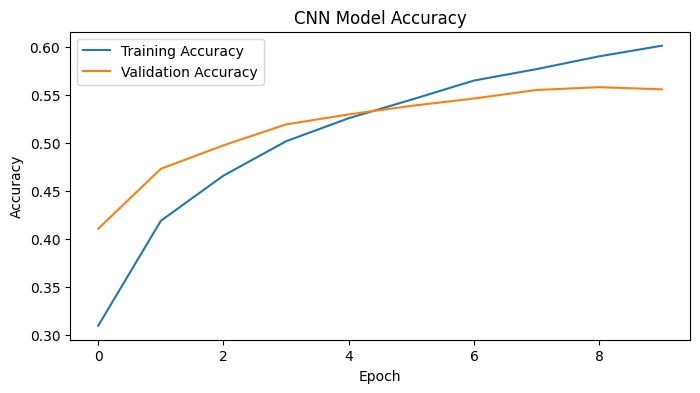

In [8]:

test_loss, test_accuracy = model.evaluate(test_data)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

# Plot accuracy
plt.figure(figsize=(8, 4))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


In [9]:

model.save("/content/emotion_model.keras")

print("Emotion model saved successfully!")


Emotion model saved successfully!


In [20]:


!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless

!pip install opencv-contrib-python-headless==4.10.0.84



Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.0/56.0 MB 60.8 MB/s  0:00:00


Saving Screenshot 2026-11-16 191348.png to Screenshot 2026-11-16 191348 (1).png
Detected Emotion: happy
Confidence: 84.96 %


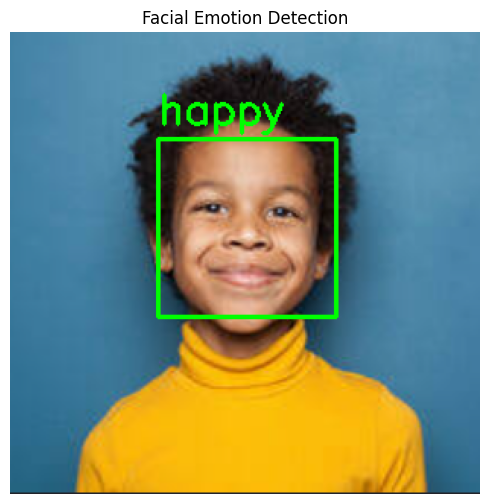

In [10]:

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

image = cv2.imread(image_path)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Face detection using Haar Cascade
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

if len(faces) == 0:
    print("No face detected. Try another image.")

else:
    for (x, y, w, h) in faces:

        face = gray[y:y+h, x:x+w]

        face = cv2.resize(face, (48, 48))

        face = face.astype("float32")
        face = np.expand_dims(face, axis=-1)
        face = np.expand_dims(face, axis=0)

        prediction = model.predict(face, verbose=0)

        emotion_index = np.argmax(prediction)
        emotion = class_names[emotion_index]

        confidence = prediction[0][emotion_index] * 100

        cv2.rectangle(
            image, (x, y), (x+w, y+h),
            (0, 255, 0), 2
        )

        cv2.putText(
            image,
            emotion,
            (x, y-10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.9,
            (0, 255, 0),
            2
        )

        print("Detected Emotion:", emotion)
        print("Confidence:", round(float(confidence), 2), "%")

    plt.figure(figsize=(8, 6))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Facial Emotion Detection")
    plt.axis("off")
    plt.show()


In [11]:

responses = {
    "angry": "You seem to be expressing anger. Take a deep breath and relax.",

    "disgust": "You seem to be expressing discomfort. Take a moment to relax.",

    "fear": "You seem worried. Take things one step at a time.",

    "happy": "You look cheerful! Keep smiling and enjoy your day!",

    "sad": "You seem to be expressing sadness. Take care of yourself.",

    "surprise": "You seem surprised! Hope it is a pleasant surprise!",

    "neutral": "You have a neutral facial expression. How can I help you?"
}

if len(faces) > 0:

    response = responses.get(
        emotion.lower(),
        "Hello! How can I help you?"
    )

    print("\n" + "=" * 45)
    print("    EMOTION-AWARE COGNITIVE ASSISTANT")
    print("=" * 45)

    print("Detected Emotion:", emotion)
    print("Assistant Response:", response)

    print("=" * 45)



    EMOTION-AWARE COGNITIVE ASSISTANT
Detected Emotion: happy
Assistant Response: You look cheerful! Keep smiling and enjoy your day!
